# ✈️ Retards et annulations des vols aux États-Unis en 2015
## Analyse exploratoire des données (EDA)

**Contexte :** le directeur marketing veut comprendre rapidement ce qui provoque les retards et les annulations de vols.
**Question centrale :** quels sont les principaux facteurs qui influencent les retards et les annulations, et comment varient-ils d'une compagnie à l'autre et d'un aéroport à l'autre ?

**Sommaire**
1. Import des librairies
2. Chargement des données
3. Premier aperçu
4. Qualité des données : valeurs manquantes, doublons, valeurs aberrantes
5. Nettoyage et préparation
6. Analyse univariée
7. Analyse bivariée : retards et annulations selon le temps, les compagnies et les aéroports
8. Causes des retards
9. Corrélations
10. Conclusion et messages clés

## 1. Import des librairies
On utilise **pandas** pour manipuler les tableaux, **numpy** pour les calculs, et **matplotlib / seaborn / plotly** pour les graphiques.

In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns



## 2. Chargement des données
Nous disposons de 3 fichiers :
| Fichier | Contenu |
|---|---|
| `flights.csv` | un vol par ligne (date, compagnie, aéroports, horaires, retards, annulation) |
| `airlines.csv` | code IATA → nom de la compagnie |
| `airports.csv` | code IATA → nom, ville, État, coordonnées GPS de l'aéroport |

⚠️ `flights.csv` compte près de 5,8 millions de lignes. On lit les horaires comme du texte pour garder le format HHMM.

In [21]:

time_cols = ["SCHEDULED_DEPARTURE", "DEPARTURE_TIME", "WHEELS_OFF", "WHEELS_ON","SCHEDULED_ARRIVAL", "ARRIVAL_TIME"]

df_flights = pd.read_csv(
    "data/flights.csv",
    dtype={col: str for col in time_cols} | {"ORIGIN_AIRPORT": str, "DESTINATION_AIRPORT": str},
    low_memory=False
)

df_airlines = pd.read_csv("data/airlines.csv")

df_airports = pd.read_csv("data/airports.csv")

print("flights:", df_flights.shape)
print("arlines :", df_airlines.shape)
print("airports :", df_airports.shape)




flights: (5819079, 31)
arlines : (14, 2)
airports : (322, 7)


## 3. Premier aperçu des données
Objectif : comprendre la structure de chaque table, c'est-à-dire sa taille, ses colonnes et le type de chaque colonne.

💻 .shape, .head(), .info(), .dtypes, .describe(), .nunique()



## 3.1 Fichier Flights.csv
( analyse de la strucutre de ce 1er fichier csv )

In [3]:
#FICHIER FLIGHTS.CSV

df_flights.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,0005,...,0408,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,0010,...,0741,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,0020,...,0811,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,0020,...,0756,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,0025,...,0259,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df_flights.info()

<class 'pandas.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              str    
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          str    
 7   ORIGIN_AIRPORT       str    
 8   DESTINATION_AIRPORT  str    
 9   SCHEDULED_DEPARTURE  str    
 10  DEPARTURE_TIME       str    
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           str    
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            str    
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    str    
 21  ARRIVAL_TIME         str    
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24  CANCELLED

In [5]:
df_flights.describe().T

,count,mean,std,min,25%,50%,75%,max
YEAR,5819079.0,2015.000000,0.000000,2015.0,2015.0,2015.0,2015.0,2015.0
MONTH,5819079.0,6.524085,3.405137,1.0,4.0,7.0,9.0,12.0
DAY,5819079.0,15.704594,8.783425,1.0,8.0,16.0,23.0,31.0
DAY_OF_WEEK,5819079.0,3.926941,1.988845,1.0,2.0,4.0,6.0,7.0
FLIGHT_NUMBER,5819079.0,2173.092742,1757.063999,1.0,730.0,1690.0,3230.0,9855.0
DEPARTURE_DELAY,5732926.0,9.370158,37.080942,-82.0,-5.0,-2.0,7.0,1988.0
TAXI_OUT,5730032.0,16.071662,8.895574,1.0,11.0,14.0,19.0,225.0
SCHEDULED_TIME,5819073.0,141.685892,75.210582,18.0,85.0,123.0,173.0,718.0
ELAPSED_TIME,5714008.0,137.006189,74.211072,14.0,82.0,118.0,168.0,766.0
AIR_TIME,5714008.0,113.511628,72.230822,7.0,60.0,94.0,144.0,690.0


In [6]:
df_flights.nunique().sort_values()

YEAR                      1
CANCELLED                 2
DIVERTED                  2
CANCELLATION_REASON       4
DAY_OF_WEEK               7
MONTH                    12
AIRLINE                  14
DAY                      31
SECURITY_DELAY          154
TAXI_OUT                184
TAXI_IN                 185
SCHEDULED_TIME          550
AIR_SYSTEM_DELAY        570
ORIGIN_AIRPORT          628
DESTINATION_AIRPORT     629
WEATHER_DELAY           632
AIR_TIME                675
LATE_AIRCRAFT_DELAY     695
ELAPSED_TIME            712
AIRLINE_DELAY          1067
DEPARTURE_DELAY        1217
ARRIVAL_DELAY          1240
SCHEDULED_DEPARTURE    1321
DISTANCE               1363
SCHEDULED_ARRIVAL      1435
WHEELS_ON              1440
WHEELS_OFF             1440
ARRIVAL_TIME           1440
DEPARTURE_TIME         1440
TAIL_NUMBER            4897
FLIGHT_NUMBER          6952
dtype: int64

In [7]:
df_airlines.head(14)

,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways
5,OO,Skywest Airlines Inc.
6,AS,Alaska Airlines Inc.
7,NK,Spirit Air Lines
8,WN,Southwest Airlines Co.
9,DL,Delta Air Lines Inc.


In [8]:
df_airports.head()

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447


### 📋 Ce que l'on observe

| # | Constat | Pourquoi c'est important | Action prévue |
|---|---|---|---|
| 1 | 5 819 079 vols, 31 colonnes, 14 compagnies, 322 aéroports (doublons non vérifiés) | Volume important : les calculs peuvent être lents | Ne garder que les colonnes utiles pour le dashboard |
| 2 | Les colonnes horaires (`SCHEDULED_DEPARTURE`…) sont en texte au format HHMM | Impossible de les analyser par heure en l'état | Extraire l'heure (0 à 23) au nettoyage |
| 3 | `YEAR` vaut toujours 2015 | Colonne sans information | Fusionner YEAR/MONTH/DAY en une colonne `DATE` |
| 4 | `CANCELLATION_REASON` est vide pour la plupart des vols | Seuls les vols annulés ont une raison | Garder, et traduire les codes A/B/C/D en libellés |
| 5 | Les 5 colonnes de causes de retard sont vides pour X % des vols | Elles ne sont remplies que pour les retards > 15 min | Analyser les causes uniquement sur les vols concernés |
| 6 | `DEPARTURE_DELAY` va de X à X min | Valeurs extrêmes possibles (retards de plusieurs heures) | Vérifier les valeurs aberrantes |
| 7 | `ORIGIN_AIRPORT` compte X valeurs uniques, plus que les 322 aéroports connus | Certains codes ne correspondent à aucun aéroport | Vérifier ces codes en section |

# 3.2 Airlines.csv 
(Analyse structure de fichier)

In [9]:
df_airlines.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   IATA_CODE  14 non-null     str  
 1   AIRLINE    14 non-null     str  
dtypes: str(2)
memory usage: 356.0 bytes


In [10]:
df_airlines.describe()


,IATA_CODE,AIRLINE
count,14,14
unique,14,14
top,UA,United Air Lines Inc.
freq,1,1


In [11]:
df_airlines.head()

,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways


In [12]:
df_airlines.head(14)

,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways
5,OO,Skywest Airlines Inc.
6,AS,Alaska Airlines Inc.
7,NK,Spirit Air Lines
8,WN,Southwest Airlines Co.
9,DL,Delta Air Lines Inc.


In [13]:
print("Doublons :", df_airlines.duplicated().sum())
print("Codes uniques :", df_airlines["IATA_CODE"].nunique())

Doublons : 0
Codes uniques : 14


### 📋 Ce que l'on observe

| # | Constat | Pourquoi c'est important | Action prévue |
|---|---|---|---|
| 1 | 2 colonnes, 14 lignes, 14 compagnies aériennes| Important : les codes IATA des compagnies aériennes | Traiter avec le 1er fichier Flight pour les codes mal écrit |
| 2 | Aucune valeur manquante (14/14 pour les 2 colonnes), aucun doublon, 14 codes uniques | La table de référence est complète et fiable : chaque code correspond à une seule compagnie | Aucun nettoyage nécessaire sur cette table |



# 3.3 Fichier Airports
(Analyse du fichier)

In [14]:
df_airports.info()

<class 'pandas.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   IATA_CODE  322 non-null    str    
 1   AIRPORT    322 non-null    str    
 2   CITY       322 non-null    str    
 3   STATE      322 non-null    str    
 4   COUNTRY    322 non-null    str    
 5   LATITUDE   319 non-null    float64
 6   LONGITUDE  319 non-null    float64
dtypes: float64(2), str(5)
memory usage: 17.7 KB


In [15]:
df_airports.describe()

,LATITUDE,LONGITUDE
count,319.000000,319.000000
mean,38.981244,-98.378964
std,8.616736,21.523492
min,13.483450,-176.646030
25%,33.652040,-110.839385
50%,39.297610,-93.403070
75%,43.154675,-82.722995
max,71.285450,-64.798560


In [16]:
df_airports.head()

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447


In [17]:
df_airports

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447
...,...,...,...,...,...,...,...
317,WRG,Wrangell Airport,Wrangell,AK,USA,56.48433,-132.36982
318,WYS,Westerly State Airport,West Yellowstone,MT,USA,44.68840,-111.11764
319,XNA,Northwest Arkansas Regional Airport,Fayetteville/Springdale/Rogers,AR,USA,36.28187,-94.30681
320,YAK,Yakutat Airport,Yakutat,AK,USA,59.50336,-139.66023


### 📋 Ce que l'on observe — `airports.csv`

| # | Constat | Pourquoi c'est important | Action prévue |
|---|---|---|---|
| 1 | 7 colonnes, 322 lignes, 322 aéroports (codes IATA uniques, aucun doublon) | Cette table sert de dictionnaire : elle traduit les codes (ex. `LAX`) en noms, villes et États | La fusionner avec `flights` pour afficher des noms lisibles |
| 2 | 3 aéroports sans coordonnées GPS : `ECP`, `PBG`, `UST` | Ces aéroports ne pourront pas être placés sur une carte | Les compléter à partir d'une source fiable, ou les exclure de la carte uniquement |
| 3 | Un seul pays (`USA`), 54 États, 308 villes | La colonne `COUNTRY` n'apporte aucune information ; certaines villes ont plusieurs aéroports | Ne pas utiliser `COUNTRY` ; analyser par État ou par aéroport plutôt que par ville |
| 4 | Les codes aéroport de `flights` doivent tous exister dans cette table | Un code absent donnerait un aéroport sans nom après la fusion | Comparer les codes des deux tables en section 4.3 |

## 4. Qualité des données
### 4.1 Valeurs manquantes
On compte les valeurs manquantes par colonne, en nombre et en pourcentage.
**À interpréter :** certaines absences sont logiques. Un vol annulé n'a pas d'heure de départ, et les colonnes de causes de retard (`WEATHER_DELAY`…) ne sont remplies que si le retard dépasse 15 minutes.





In [18]:
missing = pd.DataFrame({
    "nb_manquants": df_flights.isna().sum(),
    "pct_manquants": (df_flights.isna().mean() * 100).round(2),
})
missing[missing["nb_manquants"] > 0].sort_values("pct_manquants", ascending=False)

,nb_manquants,pct_manquants
CANCELLATION_REASON,5729195,98.46
WEATHER_DELAY,4755640,81.72
LATE_AIRCRAFT_DELAY,4755640,81.72
AIRLINE_DELAY,4755640,81.72
SECURITY_DELAY,4755640,81.72
AIR_SYSTEM_DELAY,4755640,81.72
ELAPSED_TIME,105071,1.81
AIR_TIME,105071,1.81
ARRIVAL_DELAY,105071,1.81
ARRIVAL_TIME,92513,1.59


In [19]:
# Les vols sans heure d'arrivée sont-ils les vols annulés ou déroutés ?
sans_arrivee = df_flights["ARRIVAL_TIME"].isna()
print("Vols sans heure d'arrivée :", sans_arrivee.sum())
print("Parmi eux, annulés :", df_flights.loc[sans_arrivee, "CANCELLED"].sum())
print("Parmi eux, déroutés :", df_flights.loc[sans_arrivee, "DIVERTED"].sum())

# Les causes de retard sont-elles remplies seulement pour les retards de plus de 15 min ?
cause_remplie = df_flights["WEATHER_DELAY"].notna()
print(df_flights.loc[cause_remplie, "ARRIVAL_DELAY"].describe())

Vols sans heure d'arrivée : 92513
Parmi eux, annulés : 89884
Parmi eux, déroutés : 2629
count    1.063439e+06
mean     5.891440e+01
std      6.425032e+01
min      1.500000e+01
25%      2.300000e+01
50%      3.700000e+01
75%      7.000000e+01
max      1.971000e+03
Name: ARRIVAL_DELAY, dtype: float64


### 4.2 Doublons
vérifie s'il existe des lignes en double.

In [24]:
print("Lignes entièrement dupliquées :", df_flights.duplicated().sum())

cle_vol = ["YEAR", "MONTH", "DAY", "AIRLINE", "FLIGHT_NUMBER", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]
print("Doublons sur les vols :", df_flights.duplicated(subset= cle_vol).sum())

doublons = df_flights[df_flights.duplicated(subset=cle_vol, keep=False)]
doublons.T



Lignes entièrement dupliquées : 0
Doublons sur les vols : 0


""
YEAR
MONTH
DAY
DAY_OF_WEEK
AIRLINE
FLIGHT_NUMBER
TAIL_NUMBER
ORIGIN_AIRPORT
DESTINATION_AIRPORT
SCHEDULED_DEPARTURE


### Remarque: 

- **Aucune ligne entièrement dupliquée.**
- Un seul cas où deux vols partagent la même date, compagnie, numéro et aéroport de départ : le vol **AA 803 du 29/08/2015 au départ de STT** (St. Thomas).
- Ce ne sont pas des doublons : les deux vols ont des **destinations différentes** (CLT et SJU), des distances différentes, et ils ont tous les deux été **annulés par la compagnie**. Ils n'ont pas été déroutés (`DIVERTED` = 0).
- **Décision :** on conserve les deux lignes. Pour identifier un vol de façon unique, il faut aussi tenir compte de l'**aéroport d'arrivée**.

### 4.3 Cohérence entre les tables
On vérifie que chaque code compagnie et chaque code aéroport de `flights` existe bien dans les tables de référence.

In [ ]:
codes_inconnus_cie = ~df_flights["AIRLINE"].isin(df_airlines["IATA_CODE"])
print("Vols avec une compagnie inconnue :", codes_inconnus_cie.sum())

codes_inconnus_aero = ~df_flights["ORIGIN_AIRPORT"].isin(df_airports["IATA_CODE"])
print("Vols avec un aéroport de départ inconnu :", codes_inconnus_aero.sum())

# Sur quels mois ces codes inconnus apparaissent-ils ?
df_flights.loc[codes_inconnus_aero, "MONTH"].value_counts().sort_index()

Vols avec une compagnie inconnue : 0
Vols avec un aéroport de départ inconnu : 486165


MONTH
10    486165
Name: count, dtype: int64

In [ ]:
# À quoi ressemblent les codes inconnus ?
print("Exemples de codes inconnus :", df_flights.loc[codes_inconnus_aero, "ORIGIN_AIRPORT"].unique()[:10])

# Est-ce que tous les vols d'octobre sont concernés ?
octobre = df_flights["MONTH"] == 10
print("Vols en octobre :", octobre.sum())
print("Dont code de départ inconnu :", (octobre & codes_inconnus_aero).sum())

# Même vérification pour l'aéroport d'arrivée
codes_inconnus_dest = ~df_flights["DESTINATION_AIRPORT"].isin(df_airports["IATA_CODE"])
print("Vols avec un aéroport d'arrivée inconnu :", codes_inconnus_dest.sum())
print("Dont en octobre :", (octobre & codes_inconnus_dest).sum())

Exemples de codes inconnus : <StringArray>
['14747', '14771', '12889', '12892', '14869', '10299', '11292', '14107',
 '11630', '10732']
Length: 10, dtype: str
Vols en octobre : 486165
Dont code de départ inconnu : 486165
Vols avec un aéroport d'arrivée inconnu : 486165
Dont en octobre : 486165


### Remarque :

- **Compagnies :** les codes de `flights` existent tous dans `airlines`. Aucun problème.
- **Aéroports :** les **486 165 vols d'octobre** (~8,4 % de l'année) ont des codes aéroport absents de `airports`, au départ comme à l'arrivée. **Aucun autre mois n'est concerné.**
- Pour le mois d' Octobre, la source utilise des **codes numériques à 5 chiffres** (ex. `14747`, `12889`) au lieu des codes IATA à 3 lettres (ex. `LAX`).
- **Décision :** octobre est conservé pour les analyses par mois, compagnie, heure et cause de retard, mais **exclu des analyses par aéroport** (classements, carte), faute de table de correspondance fiable.

### 4.4 Valeurs aberrantes
On cherche des valeurs extrêmes ou impossibles dans les retards et les durées.
On distingue deux cas :
- **valeur extrême** : rare mais possible (ex. un retard de 20 h). On la **garde** et on la signale ;
- **valeur impossible** : incohérente (ex. une distance négative). On la **corrige ou on l'exclut**.

**Pourquoi des percentiles ?** Le 99e percentile indique la valeur sous laquelle se trouvent 99 % des vols. Le comparer au maximum montre si quelques cas extrêmes s'éloignent du reste.

In [ ]:
cols = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "TAXI_IN",
        "AIR_TIME", "ELAPSED_TIME", "SCHEDULED_TIME", "DISTANCE"]

df_flights[cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(1)

,count,mean,std,min,1%,25%,50%,75%,99%,max
DEPARTURE_DELAY,5732926.0,9.4,37.1,-82.0,-13.0,-5.0,-2.0,7.0,168.0,1988.0
ARRIVAL_DELAY,5714008.0,4.4,39.3,-87.0,-34.0,-13.0,-5.0,8.0,167.0,1971.0
TAXI_OUT,5730032.0,16.1,8.9,1.0,6.0,11.0,14.0,19.0,50.0,225.0
TAXI_IN,5726566.0,7.4,5.6,1.0,2.0,4.0,6.0,9.0,30.0,248.0
AIR_TIME,5714008.0,113.5,72.2,7.0,23.0,60.0,94.0,144.0,337.0,690.0
ELAPSED_TIME,5714008.0,137.0,74.2,14.0,41.0,82.0,118.0,168.0,367.0,766.0
SCHEDULED_TIME,5819073.0,141.7,75.2,18.0,44.0,85.0,123.0,173.0,377.0,718.0
DISTANCE,5819079.0,822.4,607.8,21.0,100.0,373.0,647.0,1062.0,2588.0,4983.0


### Remmarque : 

- **Le vol typique n'est pas en retard** : la moitié des vols arrivent au moins 5 min en avance (médiane = -5 min).

- **99 % des vols** ont moins de **2 h 47** de retard à l'arrivée, mais le pire cas atteint **~33 h** (1 971 min). Ces cas extrêmes sont rares, on les conserve.

- La **moyenne (4,4 min)** est plus haute que la **médiane (-5 min)** : quelques très gros retards la tirent vers le haut. On utilisera la médiane pour décrire un retard typique.

- **Aucune valeur impossible** : toutes les durées et distances sont positives.
- `SCHEDULED_TIME` a 6 valeurs manquantes, un nombre négligeable.

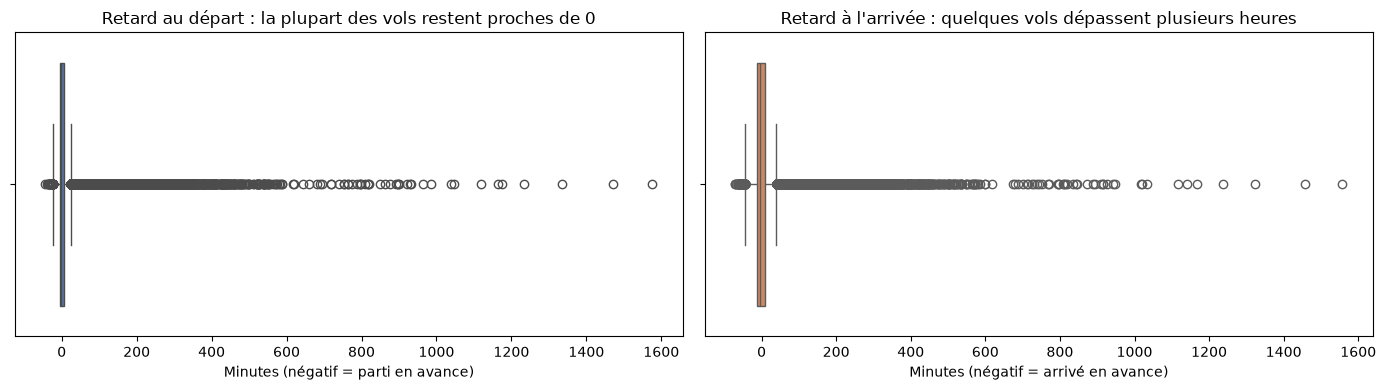

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Échantillon pour accélérer l'affichage
echantillon = df_flights.sample(200_000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=echantillon["DEPARTURE_DELAY"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Retard au départ : la plupart des vols restent proches de 0")
axes[0].set_xlabel("Minutes (négatif = parti en avance)")

sns.boxplot(x=echantillon["ARRIVAL_DELAY"], ax=axes[1], color="#DD8452")
axes[1].set_title("Retard à l'arrivée : quelques vols dépassent plusieurs heures")
axes[1].set_xlabel("Minutes (négatif = arrivé en avance)")

plt.tight_layout()
plt.show()

## 5. Nettoyage et préparation
On applique les décisions prises en section 4. **Aucune ligne n'est supprimée** : on ajoute des colonnes pour rendre les données plus lisibles et plus faciles à filtrer.

| Étape | Pourquoi |
|---|---|
| 5.1 Créer une colonne `DATE` | Analyser l'évolution dans le temps plus facilement |
| 5.2 Extraire l'heure de départ (0 à 23) | Étudier les retards selon le moment de la journée |
| 5.3 Traduire les codes d'annulation | Rendre les graphiques lisibles par un public non technique |
| 5.4 Ajouter le nom des compagnies | Afficher « American Airlines » plutôt que « AA » |
| 5.5 Marquer les codes aéroport valides | Exclure octobre des seules analyses par aéroport |
| 5.6 Créer un indicateur de retard | Calculer facilement un taux de vols en retard |
| 5.7 Convertir la distance en km | Respecter les unités utilisées en Europe |
| 5.8 Sauvegarder les données propres | Recharger rapidement, et réutiliser dans Dash |

### 5.1 Colonne date 

In [25]:
df_flights["DATE"] = pd.to_datetime(df_flights[["YEAR", "MONTH", "DAY"]])
df_flights[["YEAR", "MONTH", "DAY", "DATE"]].head()

,YEAR,MONTH,DAY,DATE
0,2015,1,1,2015-01-01
1,2015,1,1,2015-01-01
2,2015,1,1,2015-01-01
3,2015,1,1,2015-01-01
4,2015,1,1,2015-01-01


### 5.2 Heure de départ prévue

`SCHEDULED_DEPARTURE` est au format HHMM (ex. `1435` = 14h35). On garde seulement l'heure.
Minuit est parfois noté `2400` : on le ramène à 0.

In [26]:
df_flights["DEP_HOUR"] = df_flights["SCHEDULED_DEPARTURE"].str[:2].astype(int) % 24
df_flights["DEP_HOUR"].value_counts().sort_index()

DEP_HOUR
0      14664
1       5159
2       1414
3        778
4        531
5     118051
6     406940
7     393947
8     381014
9     351403
10    371644
11    358084
12    355611
13    363509
14    329715
15    367760
16    334153
17    390362
18    334380
19    331338
20    259432
21    187467
22    117551
23     44172
Name: count, dtype: int64

### 5.3 Raisons d'annulation

In [27]:
raisons = {
    "A": "Compagnie aérienne",
    "B": "Météo",
    "C": "Système aérien national",
    "D": "Sécurité",
}
df_flights["CANCELLATION_LABEL"] = df_flights["CANCELLATION_REASON"].map(raisons)
df_flights["CANCELLATION_LABEL"].value_counts(dropna=False)

CANCELLATION_LABEL
NaN                        5729195
Météo                        48851
Compagnie aérienne           25262
Système aérien national      15749
Sécurité                        22
Name: count, dtype: int64

### 5.4 Nom des compagnies

On utilise `airlines` comme dictionnaire : code → nom.
On utilise `.map()` plutôt qu'une fusion (`merge`), parce que c'est plus léger en mémoire sur 5,8 millions de lignes.

In [28]:
noms_cie = df_airlines.set_index("IATA_CODE")["AIRLINE"]
df_flights["AIRLINE_NAME"] = df_flights["AIRLINE"].map(noms_cie)

print("Noms manquants :", df_flights["AIRLINE_NAME"].isna().sum())
df_flights["AIRLINE_NAME"].value_counts()

Noms manquants : 0


AIRLINE_NAME
Southwest Airlines Co.          1261855
Delta Air Lines Inc.             875881
American Airlines Inc.           725984
Skywest Airlines Inc.            588353
Atlantic Southeast Airlines      571977
United Air Lines Inc.            515723
American Eagle Airlines Inc.     294632
JetBlue Airways                  267048
US Airways Inc.                  198715
Alaska Airlines Inc.             172521
Spirit Air Lines                 117379
Frontier Airlines Inc.            90836
Hawaiian Airlines Inc.            76272
Virgin America                    61903
Name: count, dtype: int64

### 5.5 Codes aéroport valides

In [29]:
codes_valides = df_airports["IATA_CODE"]

df_flights["AIRPORT_CODE_OK"] = (
    df_flights["ORIGIN_AIRPORT"].isin(codes_valides)
    & df_flights["DESTINATION_AIRPORT"].isin(codes_valides)
)

print(df_flights["AIRPORT_CODE_OK"].value_counts())
print(df_flights.groupby("MONTH")["AIRPORT_CODE_OK"].mean().round(3))

AIRPORT_CODE_OK
True     5332914
False     486165
Name: count, dtype: int64
MONTH
1     1.0
2     1.0
3     1.0
4     1.0
5     1.0
6     1.0
7     1.0
8     1.0
9     1.0
10    0.0
11    1.0
12    1.0
Name: AIRPORT_CODE_OK, dtype: float64


### 5.6 Indicateur de retard
Aux États-Unis, un vol est officiellement « en retard » s'il arrive avec **15 minutes ou plus** de retard.
Les vols annulés ou déroutés n'ont pas de retard mesurable : ils restent vides (`NaN`) dans cet indicateur.

In [30]:
df_flights["IS_DELAYED"] = (df_flights["ARRIVAL_DELAY"] >= 15).astype("boolean")
df_flights.loc[df_flights["ARRIVAL_DELAY"].isna(), "IS_DELAYED"] = pd.NA

print(df_flights["IS_DELAYED"].value_counts(dropna=False))
print("Taux de vols en retard :", round(df_flights["IS_DELAYED"].mean() * 100, 1), "%")

IS_DELAYED
False    4650569
True     1063439
<NA>      105071
Name: count, dtype: Int64
Taux de vols en retard : 18.6 %


### 5.7 Distance en km 

In [31]:

df_flights["DISTANCE_KM"] = (df_flights["DISTANCE"] * 1.609).round(0)
df_flights[["DISTANCE", "DISTANCE_KM"]].describe().round(0)

,DISTANCE,DISTANCE_KM
count,5819079.0,5819079.0
mean,822.0,1323.0
std,608.0,978.0
min,21.0,34.0
25%,373.0,600.0
50%,647.0,1041.0
75%,1062.0,1709.0
max,4983.0,8018.0


### 5.8 Sauvegarde des données propres
On enregistre le résultat au format **Parquet** : il est plus compact qu'un CSV, conserve les types de colonnes, et se recharge en quelques secondes. Ce fichier servira aussi à l'application Dash.

In [33]:
df_flights.to_parquet("data/flights_clean.parquet", index=False)
print("Sauvegardé :", df_flights.shape)

Sauvegardé : (5819079, 38)


In [34]:
df_flights = pd.read_parquet("data/flights_clean.parquet")